# CPPI Portfolio Insurance: Risk-Constrained Leverage

**A compact quantitative risk mini-project adapted from SF2980 Risk Management, Session 2, Problem 5.**

**Question:** How do a floor-breach probability limit and an Expected Shortfall limit constrain CPPI leverage, and what happens when market volatility rises?

This is a **one-period, model-based study**. There is no historical price data, dynamic rebalancing, or transaction-cost modeling.

## 1. Model and assumptions

The portfolio has current value $V_0$, a **floor** $G$, and a **cushion** $C=V_0-G>0$.

- Invest $\alpha C$ in the risky asset and $V_0-\alpha C$ in cash (zero interest).
- The risky asset's **gross return factor** is $R=\exp(\mu+\sigma Z)$, where $Z\sim N(0,1)$.
- The one-period future portfolio value is

$$V_1=V_0+\alpha C(R-1).$$

Here $\alpha$ multiplies the **cushion**, not the full portfolio; $G$ is a risk threshold, **not** the amount held as cash.

We choose **illustrative** $V_0=100$, $G=80$, and $\gamma=0.10$. The exercise supplies $\mu=0.05$, $\sigma=0.20$ and tail probability $p=0.01$. The illustrative dollar amounts and $\gamma$ are not given in the original exercise.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from pathlib import Path

V0, floor = 100.0, 80.0
cushion = V0 - floor
mu, sigma0 = 0.05, 0.20
p, gamma = 0.01, 0.10

figure_dir = Path("figures")
figure_dir.mkdir(exist_ok=True)


## 2. Part (a): floor-breach probability constraint

For $\alpha>1$, the requirement $P(V_1<G)\le p$ is equivalent to

$$P\left(R<1-\frac{1}{\alpha}\right)\le p.$$

Setting the bound to equality yields

$$\boxed{\alpha_a=\frac{1}{1-\exp(\mu+\sigma\Phi^{-1}(p))}}.$$

The condition concerns **probability** of falling below the floor, not the magnitude of the loss.

In [2]:
z_p = norm.ppf(p)
alpha_a = 1 / (1 - np.exp(mu + sigma0 * z_p))

print(f"Part (a) maximum leverage: {alpha_a:.4f}×")
print(f"Risky allocation: ${alpha_a * cushion:.2f}; cash: ${V0 - alpha_a*cushion:.2f}")

Part (a) maximum leverage: 2.9426×
Risky allocation: $58.85; cash: $41.15


## 3. Part (b): Expected Shortfall constraint

For a future wealth (profit) variable $X$, use the lower-tail convention

$$ES_p(X)=-E[X\mid X\text{ is in its lowest }p\text{ fraction}].$$

This sign convention expresses the average **loss** associated with bad wealth outcomes. In particular, the exercise constrains

$$ES_p(V_1-G)\le\gamma C.$$

Let $m_p=E[R\mid R\le q_p(R)]$. For the lognormal model,

$$m_p=\frac{e^{\mu+\sigma^2/2}\Phi(\Phi^{-1}(p)-\sigma)}{p}.$$

The lower-tail mean of the future cushion is $C[1+\alpha(m_p-1)]$, so

$$ES_p(V_1-G)=C[\alpha(1-m_p)-1],\qquad
\boxed{\alpha_b=\frac{1+\gamma}{1-m_p}}.$$

**Interpretation of $\gamma=0.10$:** the average portfolio value in the worst 1% of model outcomes must be **at least $G-\gamma C=78$**. The lowest 1% of outcomes are selected first; they are *not* defined as the scenarios that breach the floor.

In [3]:
def lower_tail_mean_return(mu, sigma, p):
    z = norm.ppf(p)
    return np.exp(mu + sigma**2 / 2) * norm.cdf(z - sigma) / p

m0 = lower_tail_mean_return(mu, sigma0, p)
alpha_b = (1 + gamma) / (1 - m0)

print(f"Mean gross risky return in worst 1%: {m0:.4f}")
print(f"Part (b) maximum leverage: {alpha_b:.4f}×")
print(f"Risky allocation: ${alpha_b * cushion:.2f}; cash: ${V0 - alpha_b*cushion:.2f}")
print(f"Required worst-tail mean wealth: ${floor - gamma*cushion:.2f}")

Mean gross risky return in worst 1%: 0.6181
Part (b) maximum leverage: 2.8800×
Risky allocation: $57.60; cash: $42.40
Required worst-tail mean wealth: $78.00


## 4. Compare allowable leverage

Part (a) and Part (b) have **different constraints**. The former caps the floor-breach probability; the latter caps the worst-tail *average loss relative to the floor*. They cannot automatically be called equivalent or ranked for all values of $\gamma$.

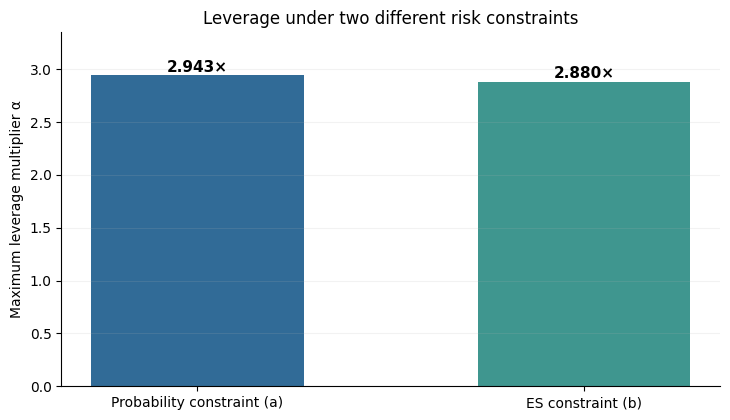

In [4]:
fig, ax = plt.subplots(figsize=(7.4, 4.3))
labels = ["Probability constraint (a)", "ES constraint (b)"]
values = [alpha_a, alpha_b]
bars = ax.bar(labels, values, color=["#316b97", "#3f968f"], width=0.55)
for bar, value in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width()/2, value + 0.035,
            f"{value:.3f}×", ha="center", fontsize=11, weight="bold")
ax.set_ylim(0, 3.35)
ax.set_ylabel("Maximum leverage multiplier α")
ax.set_title("Leverage under two different risk constraints")
ax.spines[['top','right']].set_visible(False)
ax.grid(axis="y", alpha=0.16)
fig.tight_layout()
fig.savefig(figure_dir / "leverage_comparison.png", dpi=170)
plt.show()

## 5. Part (c): simple volatility stress test

**Do not re-optimize the multipliers.** Fix the leverage levels obtained from the **baseline** model ($\sigma=0.20$), then change only $\sigma$ to 0.30 and 0.40. For each strategy compute:

1. $P(V_1<G)$ — the floor-breach probability;
2. $E[V_1\mid	ext{worst 1%}]$ — the average portfolio value in the lowest 1% of outcomes.

This is an **analytic sensitivity/stress test**, not a Monte Carlo backtest. We retain the same $\mu$ as an explicit simplifying assumption.

In [5]:
def breach_probability(alpha, mu, sigma):
    if alpha <= 1:
        return 0.0  # lognormal R > 0, hence no floor breach
    return norm.cdf(np.log(1 - 1/alpha) / sigma - mu / sigma)

def worst_tail_mean_wealth(alpha, mu, sigma, p):
    m = lower_tail_mean_return(mu, sigma, p)
    return V0 + alpha * cushion * (m - 1)

sigmas = np.array([0.20, 0.30, 0.40])
strategies = {"Probability-constrained": alpha_a, "ES-constrained": alpha_b}

for sigma in sigmas:
    print(f"σ = {sigma:.2f}")
    for name, alpha in strategies.items():
        prob = breach_probability(alpha, mu, sigma)
        w = worst_tail_mean_wealth(alpha, mu, sigma, p)
        print(f"  {name:24s} breach={prob*100:6.2f}%  worst-tail mean=${w:5.2f}")

σ = 0.20
  Probability-constrained  breach=  1.00%  worst-tail mean=$77.52
  ES-constrained           breach=  0.86%  worst-tail mean=$78.00
σ = 0.30
  Probability-constrained  breach=  6.05%  worst-tail mean=$69.08
  ES-constrained           breach=  5.61%  worst-tail mean=$69.73
σ = 0.40
  Probability-constrained  breach= 12.24%  worst-tail mean=$62.61
  ES-constrained           breach= 11.68%  worst-tail mean=$63.40


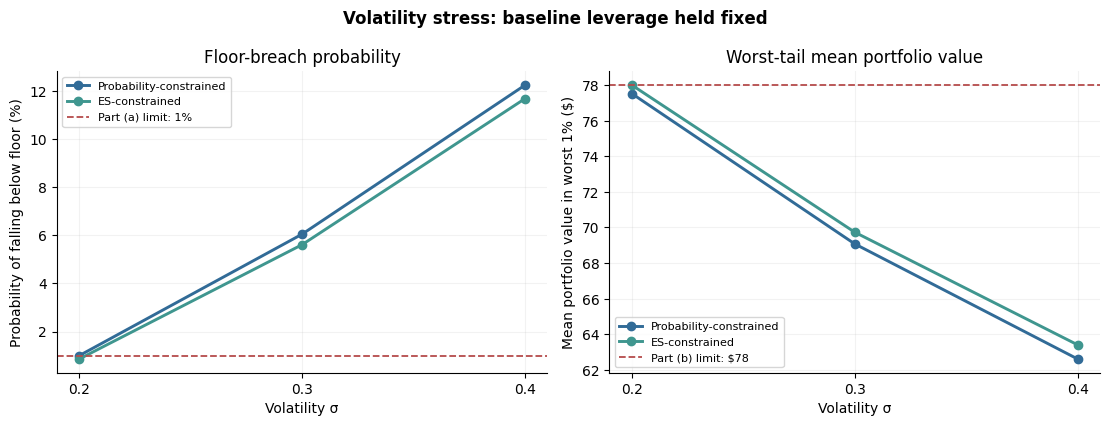

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.3))
for name, alpha in strategies.items():
    color = "#316b97" if name == "Probability-constrained" else "#3f968f"
    breach = [100 * breach_probability(alpha, mu, s) for s in sigmas]
    tail_mean = [worst_tail_mean_wealth(alpha, mu, s, p) for s in sigmas]
    axes[0].plot(sigmas, breach, marker="o", linewidth=2.1, label=name, color=color)
    axes[1].plot(sigmas, tail_mean, marker="o", linewidth=2.1, label=name, color=color)

axes[0].axhline(1.0, color="#b54b4b", linestyle="--", linewidth=1.3,
                label="Part (a) limit: 1%")
axes[0].set_ylabel("Probability of falling below floor (%)")
axes[0].set_title("Floor-breach probability")
axes[1].axhline(floor - gamma*cushion, color="#b54b4b", linestyle="--", linewidth=1.3,
                label="Part (b) limit: $78")
axes[1].set_ylabel("Mean portfolio value in worst 1% ($)")
axes[1].set_title("Worst-tail mean portfolio value")
for ax in axes:
    ax.set_xticks(sigmas)
    ax.set_xlabel("Volatility σ")
    ax.spines[['top','right']].set_visible(False)
    ax.grid(alpha=0.16)
    ax.legend(loc="best", fontsize=8)
fig.suptitle("Volatility stress: baseline leverage held fixed", weight="bold", fontsize=12)
fig.tight_layout()
fig.savefig(figure_dir / "stress_test.png", dpi=170)
plt.show()

## 6. Findings and limitations

- **At baseline volatility (20%)**, the probability-constrained strategy uses a slightly higher leverage multiple than the ES-constrained strategy when $\gamma=0.10$.
- **At higher volatility**, keeping the original leverage fixed causes both strategies to breach their respective risk limits. The point of stress testing is to discover this fragility, not to guarantee portfolio protection.
- **This is not an empirical backtest.** Results depend on the lognormal one-period model and on keeping $\mu$ fixed as $\sigma$ changes.

**Potential follow-up:** extend the model to multi-period CPPI with rebalancing and transaction costs, or use historical returns for validation.